# Analysis

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/consumer_complaints.csv')

sns.set_theme(palette='Greens_d')

df.info()

df.nunique()

<class 'pandas.DataFrame'>
RangeIndex: 891366 entries, 0 to 891365
Data columns (total 11 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   date_received                 891366 non-null  str  
 1   product                       891366 non-null  str  
 2   issue                         891366 non-null  str  
 3   company                       891366 non-null  str  
 4   state                         891366 non-null  str  
 5   submitted_via                 891366 non-null  str  
 6   date_sent_to_company          891366 non-null  str  
 7   company_response_to_consumer  891366 non-null  str  
 8   timely_response               891366 non-null  str  
 9   consumer_disputed             891366 non-null  str  
 10  complaint_id                  891366 non-null  int64
dtypes: int64(1), str(10)
memory usage: 74.8 MB


date_received                     2176
product                             18
issue                              166
company                           4485
state                               54
submitted_via                        6
date_sent_to_company              2125
company_response_to_consumer         8
timely_response                      2
consumer_disputed                    3
complaint_id                    891366
dtype: int64

## Which financial products generate the most complaints?

product
Mortgage                                                                        239642
Debt collection                                                                 169743
Credit reporting                                                                139127
Credit card                                                                      88023
Bank account or service                                                          84275
Credit reporting, credit repair services, or other personal consumer reports     57957
Student loan                                                                     38145
Consumer Loan                                                                    31291
Credit card or prepaid card                                                      11495
Checking or savings account                                                       9304
Payday loan                                                                       5519
Money transfers                    

Text(0.5, 1.0, 'Number of Complaints Sorted by Products')

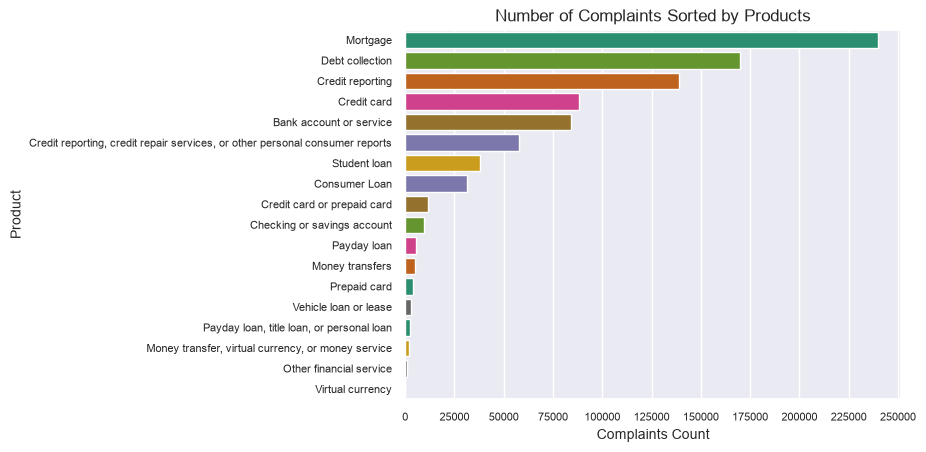

In [6]:
print(df['product'].value_counts())
print(np.around(df['product'].value_counts() / df.shape[0] * 100, 2))

g = sns.countplot(data=df, y='product', hue='product', legend=False, palette='Dark2', order=df['product'].value_counts().index)
g.set_xticks(np.arange(0, 250001, 25000))
g.tick_params(axis='both', labelsize=8)

g.set_xlabel('Complaints Count', fontsize=10)
g.set_ylabel('Product', fontsize=10)
g.set_title('Number of Complaints Sorted by Products')

## How have complaint volumes changed over time?

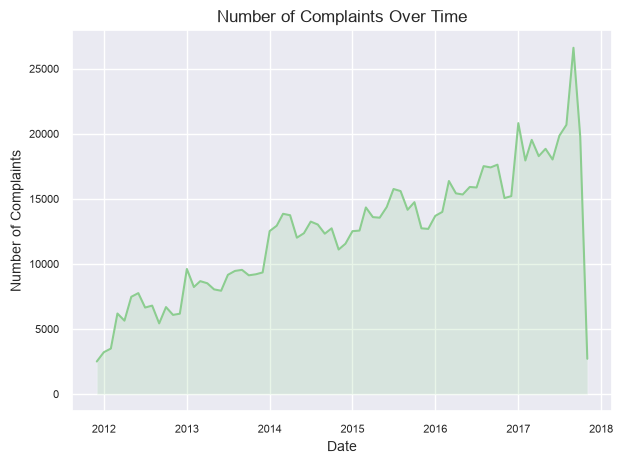

In [7]:
df['date_received'] = pd.to_datetime(df['date_received'])

monthly_complaints = df.set_index('date_received').resample('MS').size()

sns.lineplot(x=monthly_complaints.index, y=monthly_complaints.values)
plt.fill_between(monthly_complaints.index, monthly_complaints.values, alpha=0.2)

plt.tick_params(axis='both', labelsize=8)

plt.title('Number of Complaints Over Time')
plt.xlabel('Date', fontsize=10)
plt.ylabel('Number of Complaints', fontsize=10)
plt.tight_layout()

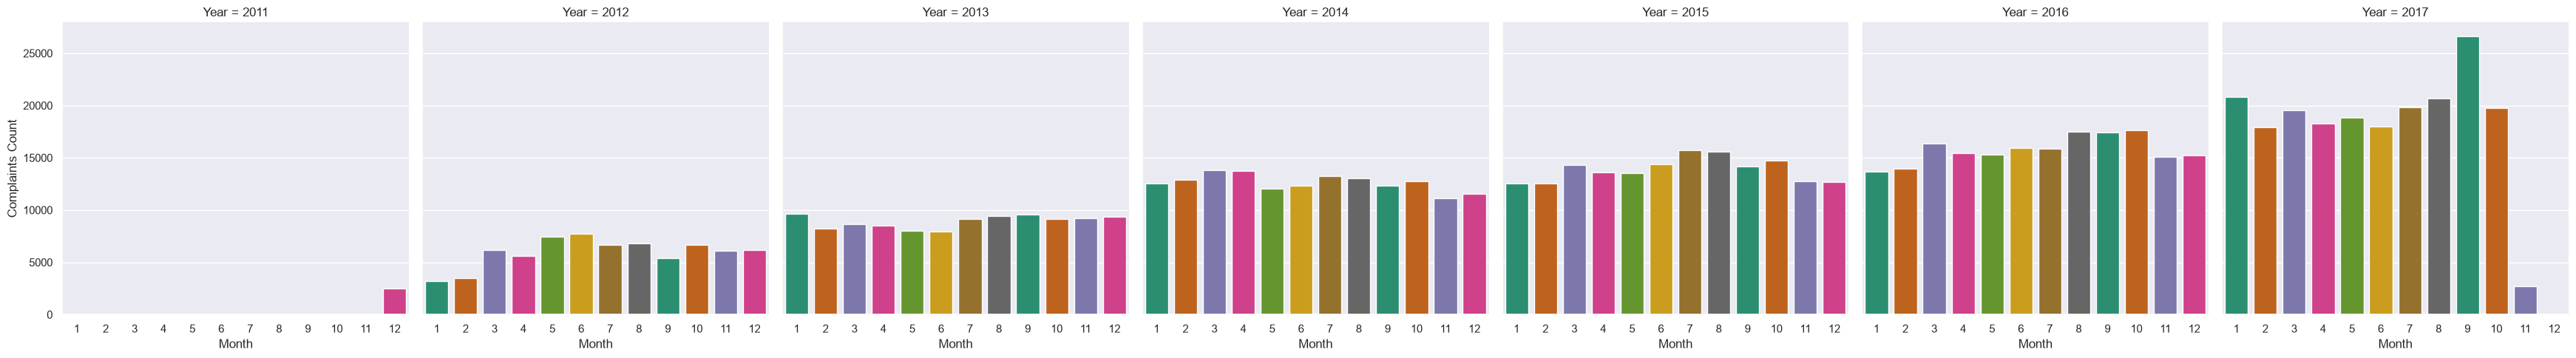

In [8]:
df['Year'] = df['date_received'].dt.year
df['month'] = df['date_received'].dt.month

f = sns.catplot(data=df, x='month', col='Year', hue='month', kind='count', legend=False, palette='Dark2')

f.set_axis_labels('Month', 'Complaints Count')

## Which issues have the highest share of disputed complaints?

In [9]:
issue_disputed = (
    df.groupby('issue')['consumer_disputed']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .nlargest(5)
    .sort_values()
)

print(issue_disputed)

issue
Application, originator, mortgage broker    25.863783
Settlement process and costs                27.488739
Cash advance                                27.800830
Lender sold the property                    40.000000
Lender damaged or destroyed property        66.666667
Name: consumer_disputed, dtype: float64


Text(0.5, 1.0, 'Percentage of Disputed Complaints by Issue')

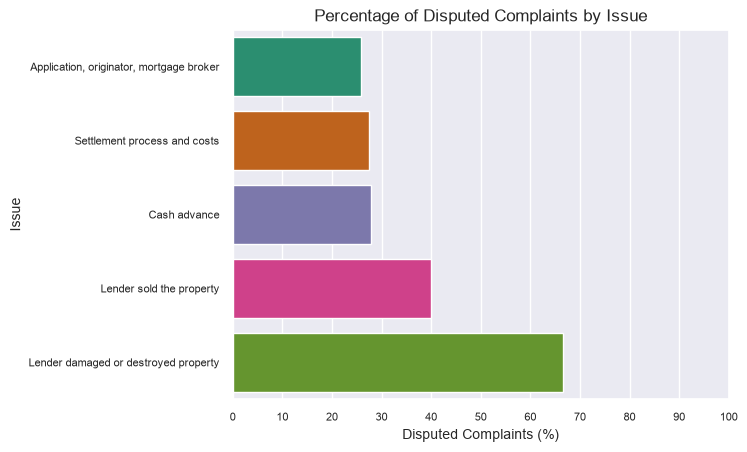

In [10]:
g = sns.barplot(x=issue_disputed.values, y=issue_disputed.index, hue=issue_disputed.values, legend=False, palette='Dark2')

g.set_xticks(np.arange(0, 101, 10))
g.tick_params(axis='both', labelsize=8)

g.set_xlabel('Disputed Complaints (%)', fontsize=10)
g.set_ylabel('Issue', fontsize=10)
g.set_title('Percentage of Disputed Complaints by Issue')

## Which factors are associated with timely company responses?

In [71]:
timely_response_by_submitted_channel = (
    df.groupby('submitted_via')['timely_response']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values()
)

print(np.around(timely_response_by_submitted_channel, 2))

submitted_via
Phone          96.88
Email          97.05
Web            97.06
Fax            97.66
Referral       97.98
Postal mail    98.20
Name: timely_response, dtype: float64


Text(0.5, 1.0, 'Positive Timely Response by Submission Channel')

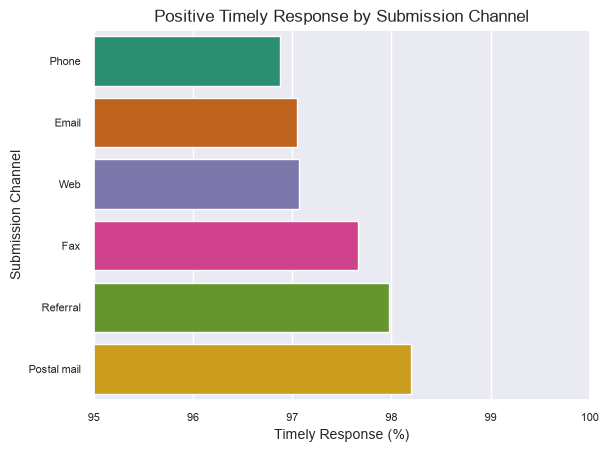

In [42]:
g = sns.barplot(
    x=timely_response_by_submitted_channel.values, 
    y=timely_response_by_submitted_channel.index,
    hue=timely_response_by_submitted_channel.values,
    legend=False,
    palette='Dark2'
)

g.set_xlim(95, 100)
g.set_xticks(np.arange(95, 101, 1))
g.tick_params(axis='both', labelsize=8)

g.set_xlabel('Timely Response (%)', fontsize=10)
g.set_ylabel('Submission Channel', fontsize=10)
g.set_title('Positive Timely Response by Submission Channel')

In [48]:
highest_timely_responses_by_product = (
    df.groupby('product')['timely_response']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .nlargest(3)
    .sort_values()
)

lowest_timely_responses_by_product = (
    df.groupby('product')['timely_response']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .nsmallest(3)
    .sort_values()
)

print(np.around(highest_timely_responses_by_product, 2))
print(np.around(lowest_timely_responses_by_product, 2))

product
Credit card                    98.90
Credit card or prepaid card    99.36
Credit reporting               99.79
Name: timely_response, dtype: float64
product
Virtual currency           88.24
Payday loan                89.09
Other financial service    89.18
Name: timely_response, dtype: float64


Text(0.5, 1.0, 'Positive Timely Response by Product')

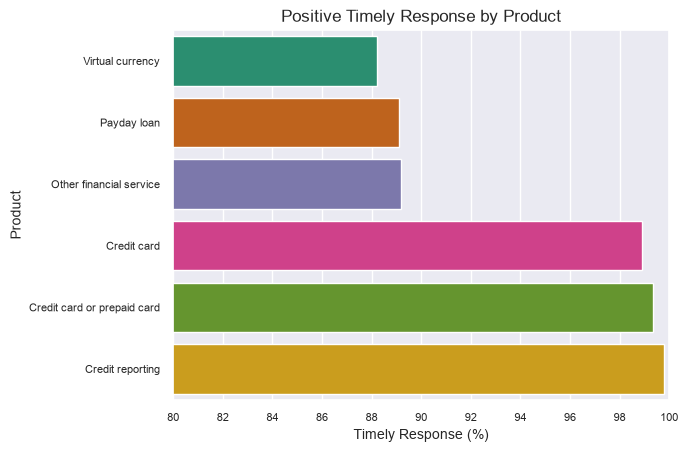

In [86]:
product_data = pd.concat([
    lowest_timely_responses_by_product,
    highest_timely_responses_by_product
])

g = sns.barplot(
    x=product_data.values, 
    y=product_data.index,
    hue=product_data.values,
    legend=False,
    palette='Dark2'
)

g.set_xlim(80, 100)
g.set_xticks(np.arange(80, 101, 2))
g.tick_params(axis='both', labelsize=8)

g.set_xlabel('Timely Response (%)', fontsize=10)
g.set_ylabel('Product', fontsize=10)
g.set_title('Positive Timely Response by Product')

In [50]:
highest_timely_responses_by_issue = (
    df.groupby('issue')['timely_response']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .nlargest(5)
    .sort_values()
)

lowest_timely_responses_by_issue = (
    df.groupby('issue')['timely_response']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .nsmallest(5)
    .sort_values()
)

print(np.around(highest_timely_responses_by_issue, 2))
print(np.around(lowest_timely_responses_by_issue, 2))

issue
Advertising, marketing or disclosures                       100.0
Convenience checks                                          100.0
Credit limit changed                                        100.0
Lender damaged or destroyed vehicle                         100.0
Managing, opening, or closing your mobile wallet account    100.0
Name: timely_response, dtype: float64
issue
Lender damaged or destroyed property          66.67
Problem with credit report or credit score    75.00
Lender sold the property                      80.00
Can't contact lender or servicer              84.52
Excessive fees                                85.59
Name: timely_response, dtype: float64


In [82]:
issue_response = (
    df.groupby('issue')['timely_response']
    .agg(
        total='count',
        timely=lambda x: (x == 'Yes').sum(),
        rate=lambda x: (x == 'Yes').mean() * 100
    )
)

issue_response = issue_response.sort_values('rate', ascending=False)

issue_response_filtered = issue_response[issue_response['total'] > 100]

print(issue_response_filtered)

                                                    total  timely        rate
issue                                                                        
Convenience checks                                    148     148  100.000000
Unauthorized transactions or other transaction ...    108     108  100.000000
Managing, opening, or closing your mobile walle...    117     117  100.000000
Unable to get credit report/credit score            10683   10672   99.897033
Credit reporting company's investigation            16796   16776   99.880924
...                                                   ...     ...         ...
Taking/threatening an illegal action                 8804    7822   88.845979
Charged bank acct wrong day or amt                    296     260   87.837838
Received a loan I didn't apply for                    616     539   87.500000
Can't contact lender                                 1096     940   85.766423
Excessive fees                                        118     10

## Are there differences by submission channel or region?

In [96]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891366 entries, 0 to 891365
Data columns (total 13 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   date_received                 891366 non-null  datetime64[us]
 1   product                       891366 non-null  str           
 2   issue                         891366 non-null  str           
 3   company                       891366 non-null  str           
 4   state                         891366 non-null  str           
 5   submitted_via                 891366 non-null  str           
 6   date_sent_to_company          891366 non-null  str           
 7   company_response_to_consumer  891366 non-null  str           
 8   timely_response               891366 non-null  str           
 9   consumer_disputed             891366 non-null  str           
 10  complaint_id                  891366 non-null  int64         
 11  Year                    

Text(141.91216362847223, 0.5, 'State')

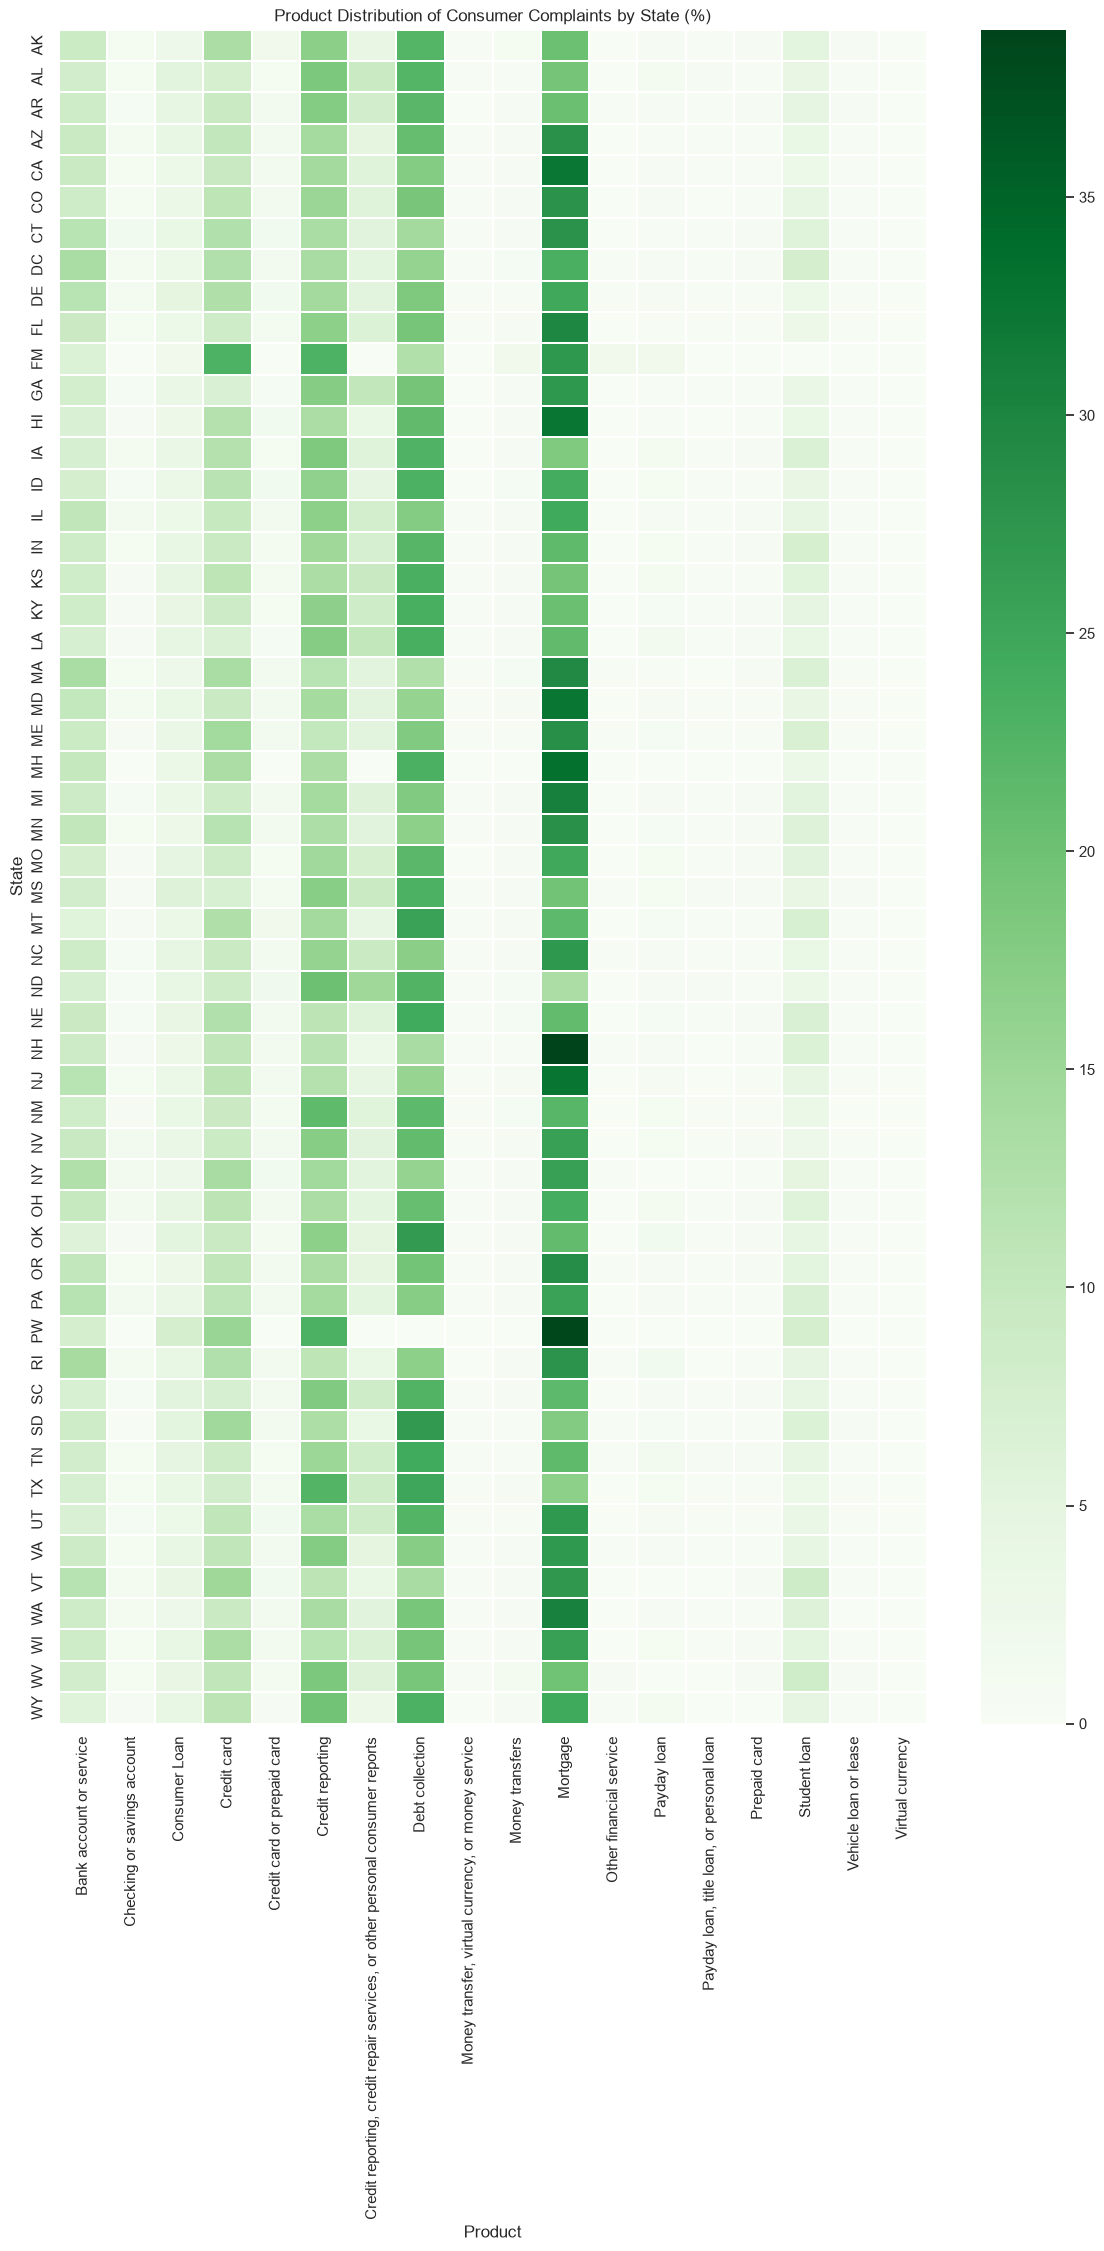

In [109]:
state_product = pd.crosstab(
    df['state'],
    df['product'],
    normalize='index'
) * 100

plt.figure(figsize=(14, 22))

sns.heatmap(
    state_product,
    cmap='Greens',
    linewidths=0.3,
    annot=False,
    fmt='.1f'
)

plt.title('Product Distribution of Consumer Complaints by State (%)')
plt.xlabel('Product')
plt.ylabel('State')

Text(46.91216362847219, 0.5, 'Product')

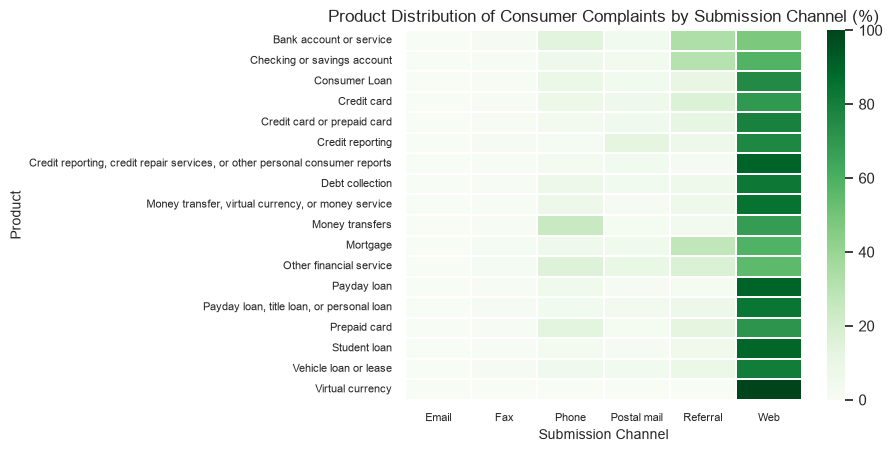

In [114]:
submission_channel_product = pd.crosstab(
    df['product'],
    df['submitted_via'],
    normalize='index'
) * 100

sns.heatmap(
    submission_channel_product,
    cmap='Greens',
    linewidths=0.3,
    annot=False,
    fmt='.1f'
)

plt.tick_params(axis='both', labelsize=8)

plt.title('Product Distribution of Consumer Complaints by Submission Channel (%)')
plt.xlabel('Submission Channel', fontsize=10)
plt.ylabel('Product', fontsize=10)